# W10B · A · 같은 확산 모델의 전체/LoRA·prior 비교

2026-11-04 · 『핸즈온 생성형 AI』7장 전체 · 패키지0.1.17 / 2026-fall-w10b

Drive에 새 사본을 저장하고 첫 셀부터 독립 실행하세요. 다른 노트북의 변수·파일·어댑터, API키·개인 사진·유료 GPU는 필수가 아닙니다. 다운로드/실행 실패를 가짜 결과로 대체하지 않습니다. 설치한 이전 버전을 import했다면 런타임을 재시작합니다.

예측 → 중간값 → 한 조건 변경 → 근거·한계 → 코드 없는 새 사례 설명을 기록합니다. `my_...=None`은 독립 연습 변수라 기본 흐름을 막지 않습니다.

[강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10b/course/notion/w10b/w10b-lesson.md) · [기록지·점검](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10b/course/notion/w10b/w10b-workbook.md) · [실제 API 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10b/src/W10B-API.md)

CPU에서 실제 사전학습된28×28 class-conditioned pixel denoiser를 적응시킵니다. Stable Diffusion·텍스트 DreamBooth의 완전 재현이 아닙니다. 기본16 update×네 조건은 수초 규모이지만 환경별 실측을 확인하세요. checkpoint·8개 자체 이미지·사전 SD기록은 패키지에 포함되어 자동 준비됩니다. 최초 의존성 설치 외에 A는 대형 모델을 받지 않습니다.

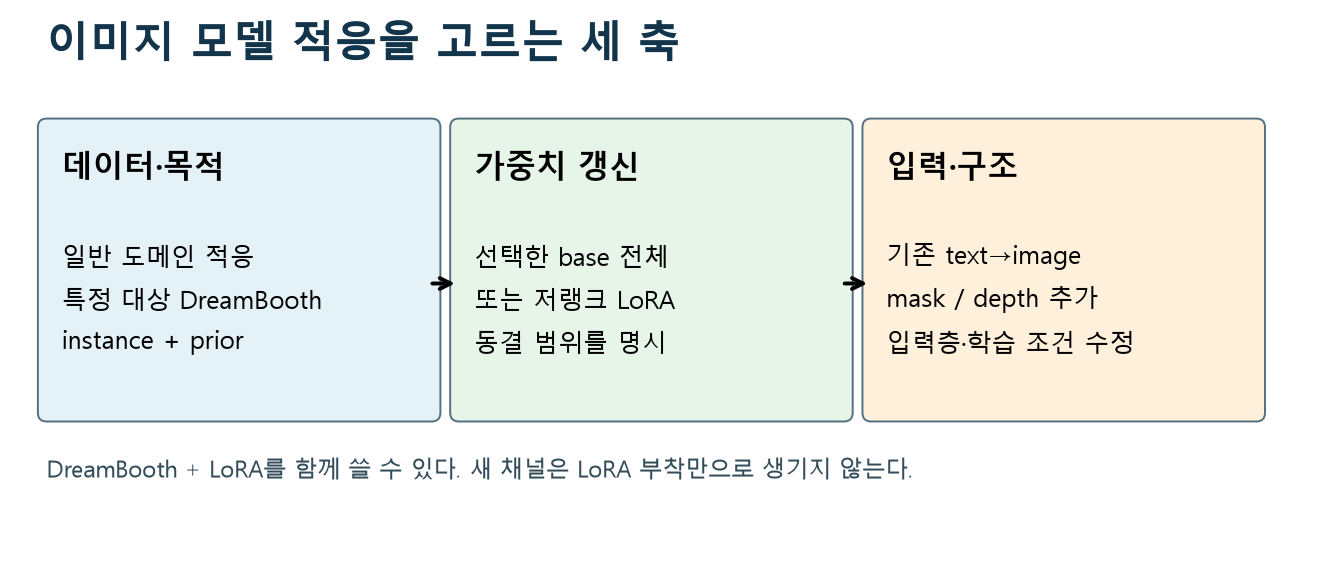


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w10b/course/notion/w10b/assets/01-method-map.png)


In [ ]:
import sys,subprocess,os,json,time,uuid
from pathlib import Path
from importlib.metadata import version,PackageNotFoundError
PUBLIC_REF='2026-fall-w10b'
try: ready=all(version(p)==v for p,v in [('luna-genai','0.1.17'),('diffusers','0.40.0'),('peft','0.21.2'),('accelerate','1.15.0'),('gradio','6.26.0')])
except PackageNotFoundError: ready=False
if not ready:
 if 'luna_genai' in sys.modules:raise RuntimeError('이미 이전 버전을 import했습니다. 런타임을 재시작하고 첫 셀부터 실행하세요.')
 package=str(Path('src').resolve())+'[diffusion-adaptation]' if Path('src/pyproject.toml').exists() else "luna-genai[diffusion-adaptation] @ "+f'git+https://github.com/lunalab-ai/genAI.git@{PUBLIC_REF}#subdirectory=src'
 subprocess.run([sys.executable,'-m','pip','install','-q','-e',package] if Path('src/pyproject.toml').exists() else [sys.executable,'-m','pip','install','-q',package],check=True)
from luna_genai.runtime import prepare_text_runtime
removed=prepare_text_runtime(repair_optional=True)
import torch,numpy as np,pandas as pd
from IPython.display import display
torch.set_num_threads(4)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
RUN_ID=uuid.uuid4().hex[:8]
print('Python',sys.version.split()[0],'luna-genai',version('luna-genai'),'torch',torch.__version__,'CUDA',torch.cuda.is_available())
print('실제로 복구한 선택 패키지:',removed)


In [ ]:
from luna_genai.diffusion_adaptation import load_teaching_images,run_tiny_comparison,TinyAdaptationLab,prior_loss_components
from luna_genai.diffusion_adaptation_app import build_tiny_app,tiny_view,export_observation
from luna_genai.diffusion import forward_noise
data=load_teaching_images()
display(pd.DataFrame(data['manifest']['images'])[['id','split','caption','group_id']])
display(data['rgb'][0]);print('CPU train/validation',data['train'].shape,data['validation'].shape)
caption_candidates=[{'id':'C1','image':'instance-00','candidate':'a photo of a red ceramic mug'},{'id':'C2','image':'instance-06','candidate':'a photo of a blue shoe'}]
display(pd.DataFrame(caption_candidates))
my_data_audit=None;my_caption_fixes=None


### A1 · 필수 · 데이터와 caption 감사

instance-00과06은 같은 물체의 다른 시점이다. 원본/시점/배경 분리를 설명하라. 진단용 후보 C1 `a photo of a red ceramic mug`와 C2 `a photo of a blue shoe`를 실제 가방 렌더와 대조해 수정하라. 대상 이름과 photo/illustration 표현을 함께 확인하고 미사용 배경 prompt를 하나 작성하라. 이 후보는 오류 찾기용이며 실제 훈련 metadata와 구별한다.

힌트: manifest의 split·camera·caption과 RGB 이미지를 함께 보세요.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


## 학습 경로를 직접 추적하기

아래는 완성 예제입니다. 실제 noise를 정답으로 사용합니다. 깨끗한 이미지 복원이 정답인 autoencoder와 구별하세요.


In [ ]:
g=torch.Generator().manual_seed(123)
clean=data['train'][:2];noise=torch.randn(clean.shape,generator=g);t=torch.tensor([24,74]);condition=torch.full((2,),8,dtype=torch.long)
noisy=forward_noise(clean,t,noise)
base=TinyAdaptationLab('frozen')
with torch.no_grad():prediction=base.model(noisy,t,condition)
display(pd.DataFrame([{'tensor':k,'shape':list(v.shape)} for k,v in [('clean',clean),('noisy',noisy),('prediction',prediction),('target_noise',noise)]]))
print('실제 epsilon MSE',float((prediction-noise).square().mean()))
my_target=None


### A2 · 필수 · 노이즈 정답과 실제 갱신

실제 작은 모델에서 clean/noisy/prediction/target의 shape와 정답을 추적하라. frozen/full/LoRA의 trainable_base·adapter 변화량을 예측하고 실행 증거와 대조하라.

힌트: 정답은 이미지의 클래스ID가 아니라 주입한 noise입니다.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


In [ ]:
# 완성 수계산 예: 제곱오차 .25,1의 평균과 .5,.5의 평균을 결합합니다.
p=torch.tensor([[.5],[1.],[.5**.5],[.5**.5]],requires_grad=True)
loss_example=prior_loss_components(p,torch.zeros_like(p),2,.5)
print({k:float(v.detach()) for k,v in loss_example.items()})
my_instance=None;my_prior=None;my_total=None


### A3 · 필수 · 두 손실과 identifier

instance 오차제곱 [1,3], prior 오차제곱 [2,2,2,2], lambda=0.25에서 두 평균과 total을 계산하라. lunabag가 한 토큰인지 실제 tokenizer로 확인하고 의미를 설명하라.

힌트: 각 집합의 분모를 따로 쓰고 마지막에 가중합합니다.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


In [ ]:
# 고정된 시작 checkpoint, 데이터, noise/t, update16을 공유하는 네 개의 실제 학습입니다.
started=time.perf_counter();comparison=run_tiny_comparison(steps=16,rank=4,seed=42)
display(comparison['table']);print('비교 전체 실측 초',time.perf_counter()-started)
lab=comparison['cases']['lora_prior1']
display(lab.state());display(lab.training['first_gradients'])
reload_check=lab.save_reload_check(f'.build/w10b-{RUN_ID}-tiny',data['validation'])
display(reload_check)
my_prior_interpretation=None


### A4 · 필수 · prior 보존의 반례

lambda0/1의 같은 모델 쌍에서 미사용 대상·기존 클래스·무관 클래스의 공통 MSE를 비교하라. prior를 넣으면 모든 지표가 좋아진다는 주장을 지지하는가?

힌트: 학습 total이 다른 목적함수이면 직접 순위화하지 않습니다.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


## 독립 확장과 설명 callback

rank2/4는 새 모델에서 다시 학습해야 합니다. 앱의 조건 선택은 이미 학습한 객체를 재사용합니다. 아래 설명 함수는 직접 작성할 자리입니다. 기본 샘플링·표·JSON 검증은 빈 답변과 독립입니다.


### X1 · 선택 · rank 통제

rank2/4에서 alpha/r=2, 동일 checkpoint·data·noise·16 update를 유지해 모수 수와 공통 평가를 비교하라.

자신의 근거와 다음 실험을 적으세요.


In [ ]:
my_rank_comparison=None
my_effective_batch=None
def learner_note(prediction,observation,controlled,limitation):
 return 'TODO: 예측·관측·통제 조건·근거와 한계를 자신의 문장으로 연결하세요.'


### X2 · 선택 · 누적 배치

instance2+prior2의 microbatch, accumulation3의 실제 배치 수를 계산하고 loss/3의 이유를 설명하라.

자신의 근거와 다음 실험을 적으세요.


## 마지막 웹앱

두 탭에서 학습된 조건·표본·설정 JSON과 자신의 설명을 확인합니다. 같은 앱에서 두 조건을 바꾸기 전에 하나만 바꿉니다. 마지막 실험 JSON을 내려받아 mode·seed·update와 자기 설명이 함께 있는지 확인하세요. 공유 주소는 현재 런타임 동안 유지됩니다. Colab 인라인 JavaScript 오류가 나면 새 셀에서 `print(app.share_url)`을 실행해 새 탭으로 여세요.


In [ ]:
app=build_tiny_app(comparison,note_fn=learner_note)
app.launch(share=IN_COLAB,prevent_thread_lock=True,quiet=True)
print('앱 주소:',app.share_url if IN_COLAB else app.local_url)


In [ ]:
assert lab.state()['trainable_base']==0 and lab.state()['trainable_adapter']==2816
assert lab.training['base_unchanged'] and any(v>0 for v in lab.training['parameter_changes'].values())
assert reload_check['max_abs_prediction_error']<=1e-6
assert len(comparison['table'])==5 and np.isfinite(comparison['table'].select_dtypes('number')).all().all()
table,gallery,payload=tiny_view(comparison,'full_prior0',43)
assert len(gallery)==2 and payload['case']=='full_prior0'
download=Path(export_observation(payload,'실제 runtime callback 검사'))
assert json.loads(download.read_text(encoding='utf-8'))['observation']['sampling_seed']==43
print('W10B_A_RUNTIME_PASS · 실제 CPU 네 조건 학습/동결/갱신/공통평가/복원/앱 callback')
if not IN_COLAB:app.close()
